In [11]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [12]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "processed"

CHART_PATH = PROJECT_ROOT / "reports" / "charts"
CHART_PATH.mkdir(parents=True, exist_ok=True)

In [13]:
fund_master = pd.read_csv(DATA_PATH / "clean_fund_master.csv")
nav = pd.read_csv(DATA_PATH / "clean_nav.csv")
transactions = pd.read_csv(DATA_PATH / "clean_transactions.csv")
performance = pd.read_csv(DATA_PATH / "clean_performance.csv")
aum = pd.read_csv(DATA_PATH / "clean_aum.csv")
sip = pd.read_csv(DATA_PATH / "clean_monthly_sip.csv")
category_inflows = pd.read_csv(DATA_PATH / "clean_category_inflows.csv")
industry_folio = pd.read_csv(DATA_PATH / "clean_industry_folio_count.csv")
portfolio = pd.read_csv(DATA_PATH / "clean_portfolio_holdings.csv")
benchmark = pd.read_csv(DATA_PATH / "clean_benchmark_indices.csv")

In [14]:
datasets = {
    "Fund Master": fund_master,
    "NAV": nav,
    "Transactions": transactions,
    "Performance": performance,
    "AUM": aum,
    "SIP": sip,
    "Category Inflows": category_inflows,
    "Industry Folio": industry_folio,
    "Portfolio": portfolio,
    "Benchmark": benchmark
}

for name, data in datasets.items():
    print(f"\n{name}: {data.shape}")
    print(data.columns.tolist())


Fund Master: (40, 15)
['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

NAV: (46000, 3)
['amfi_code', 'date', 'nav']

Transactions: (32778, 13)
['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']

Performance: (40, 21)
['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade', 'negative_sharpe_flag', 'expense_ratio_valid']

AUM: (90, 5)
['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']

SIP: (48, 6)
['month', 's

### NAV Trend Analysis

In [15]:
nav["date"] = pd.to_datetime(nav["date"])
nav = nav.sort_values("date")

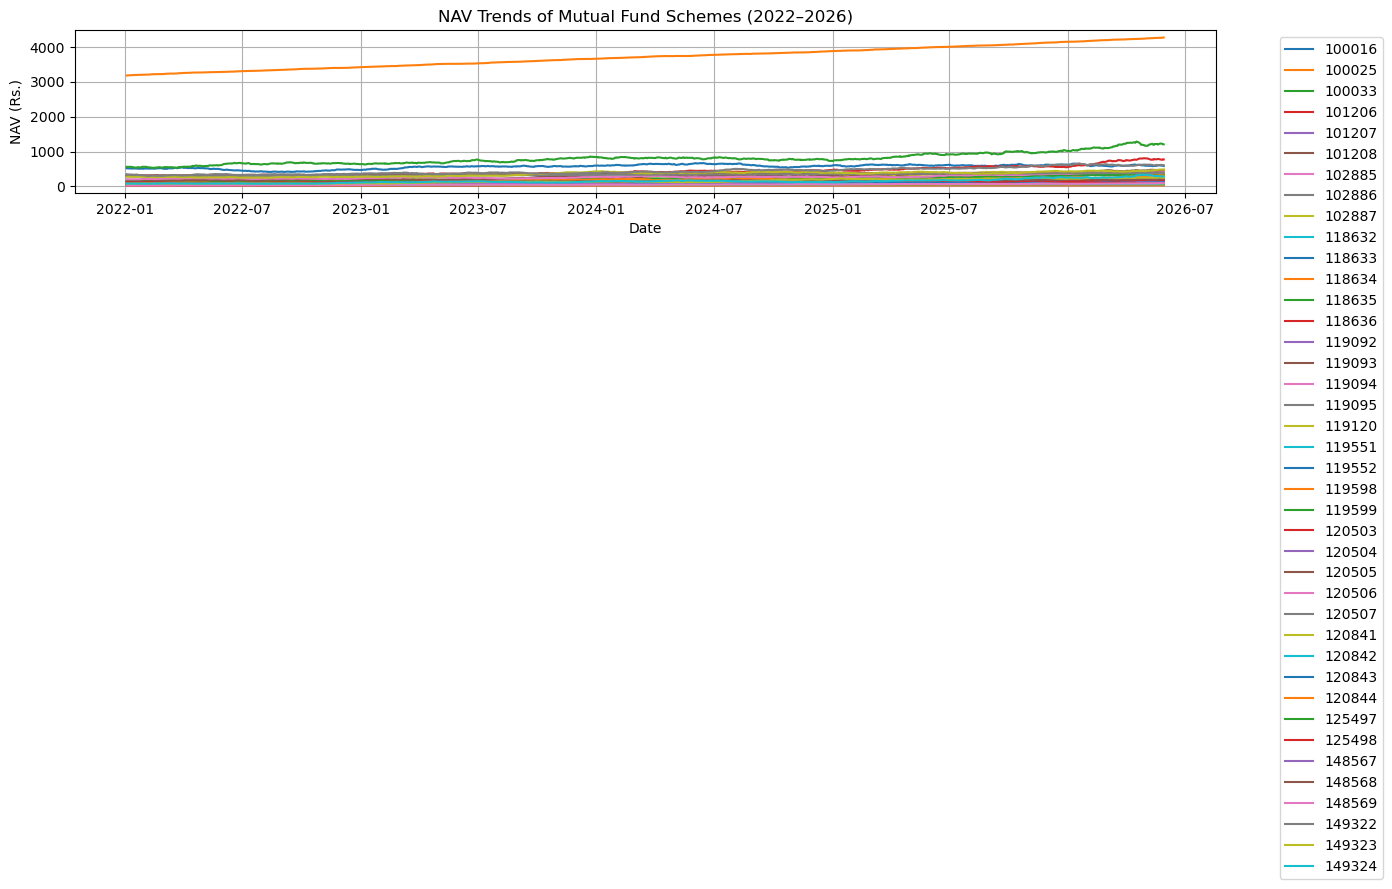

In [16]:
plt.figure(figsize=(14, 6))

for code, data in nav.groupby("amfi_code"):
    plt.plot(data["date"], data["nav"], label=code)

plt.title("NAV Trends of Mutual Fund Schemes (2022–2026)")
plt.xlabel("Date")
plt.ylabel("NAV (Rs.)")
plt.grid()
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

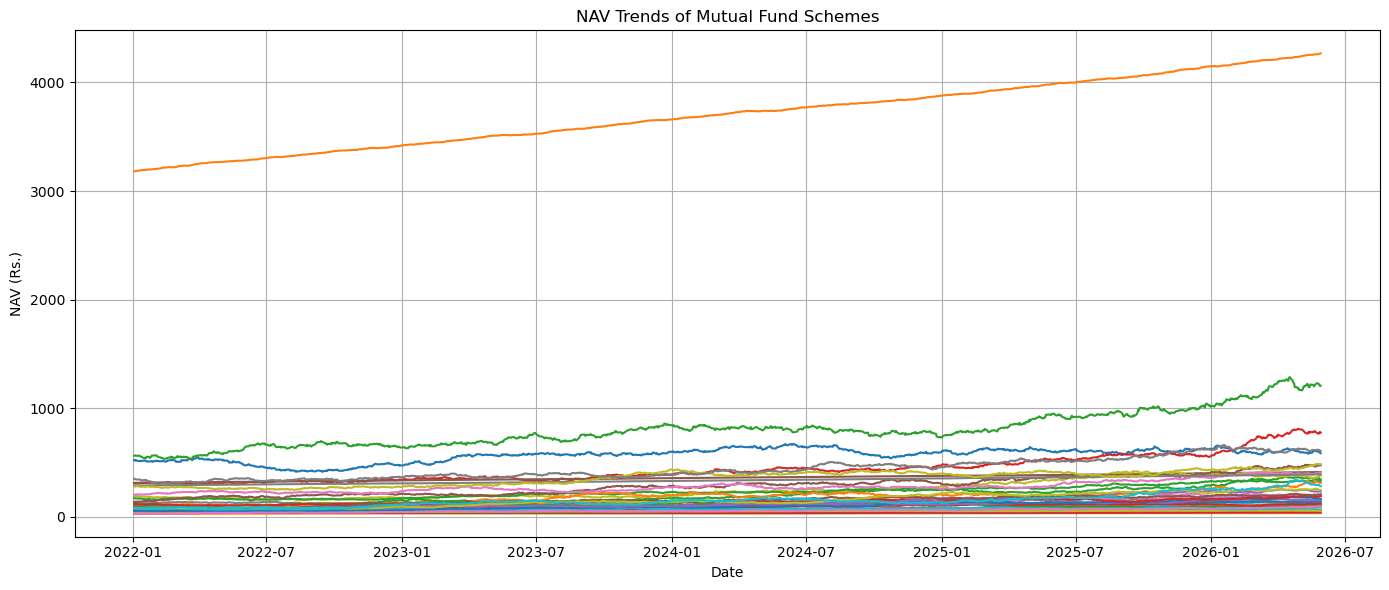

In [17]:
plt.figure(figsize=(14, 6))

for code, data in nav.groupby("amfi_code"):
    plt.plot(data["date"], data["nav"])

plt.title("NAV Trends of Mutual Fund Schemes")
plt.xlabel("Date")
plt.ylabel("NAV (Rs.)")
plt.grid()
plt.tight_layout()

plt.savefig(CHART_PATH / "nav_trends.png")
plt.show()

#### AUM Growth by AMC

In [18]:
aum["date"] = pd.to_datetime(aum["date"])
aum["year"] = aum["date"].dt.year

In [20]:
import seaborn as sns

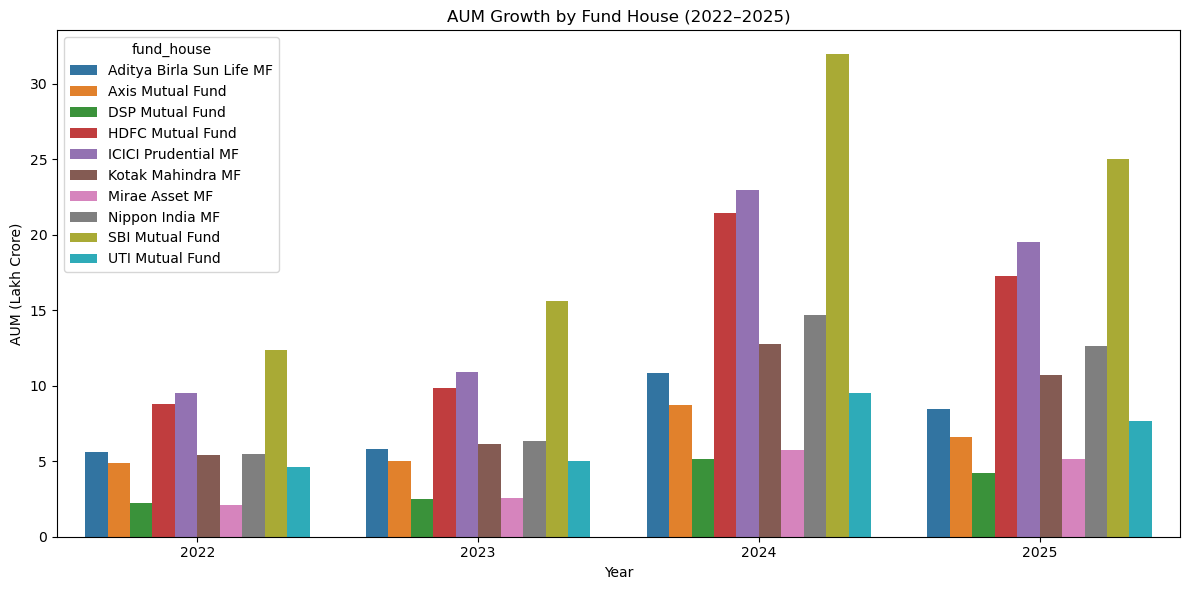

In [21]:
aum_yearly = aum.groupby(
    ["year", "fund_house"]
)["aum_lakh_crore"].sum().reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(data=aum_yearly, x="year", y="aum_lakh_crore", hue="fund_house")

plt.title("AUM Growth by Fund House (2022–2025)")
plt.xlabel("Year")
plt.ylabel("AUM (Lakh Crore)")
plt.tight_layout()
plt.show()

In [22]:
plt.savefig(CHART_PATH / "aum_growth.png")

<Figure size 640x480 with 0 Axes>

### SIP Inflow Time-Series

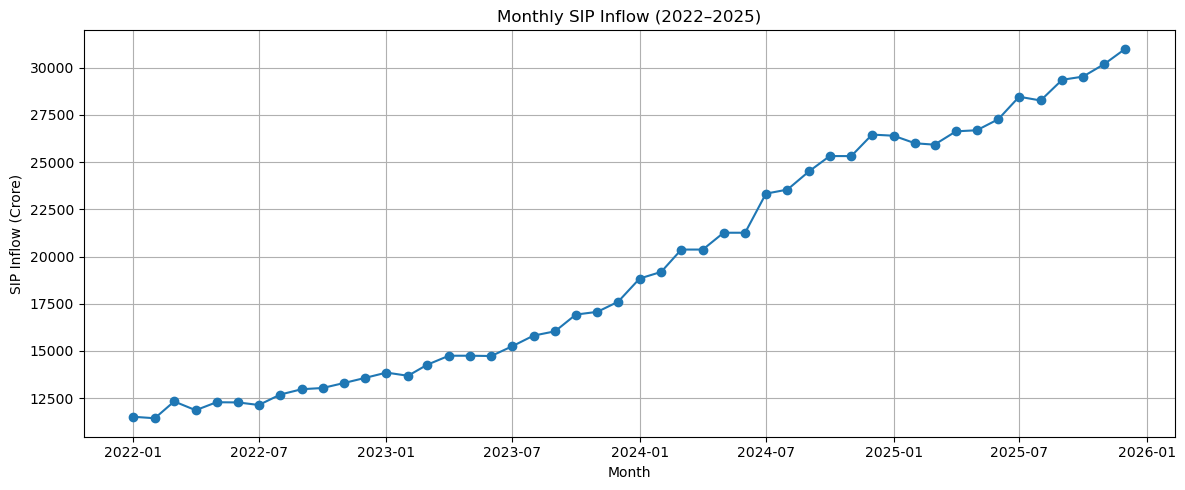

In [23]:
sip["month"] = pd.to_datetime(sip["month"])
sip = sip.sort_values("month")

plt.figure(figsize=(12, 5))

plt.plot(sip["month"], sip["sip_inflow_crore"], marker="o")

plt.title("Monthly SIP Inflow (2022–2025)")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (Crore)")
plt.grid()
plt.tight_layout()

plt.savefig(CHART_PATH / "sip_inflow_trend.png")
plt.show()

### Category-wise Inflow Heatmap

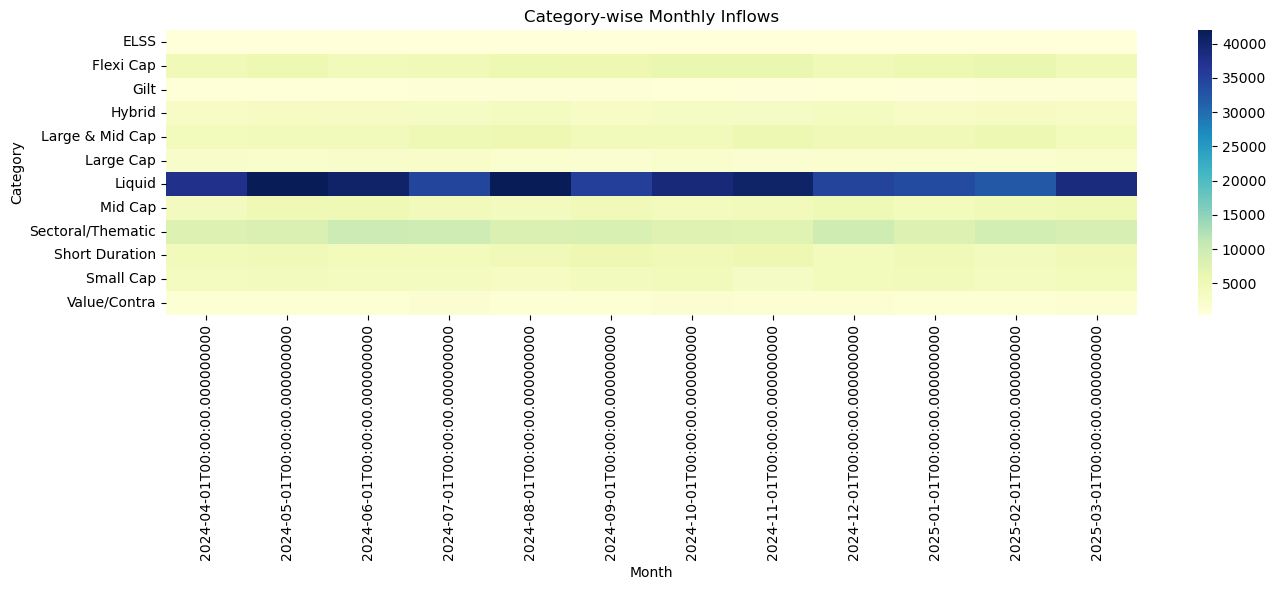

In [24]:
category_inflows["month"] = pd.to_datetime(category_inflows["month"])

heatmap_data = category_inflows.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

plt.figure(figsize=(14, 6))

sns.heatmap(heatmap_data, cmap="YlGnBu")

plt.title("Category-wise Monthly Inflows")
plt.xlabel("Month")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(CHART_PATH / "category_heatmap.png")
plt.show()

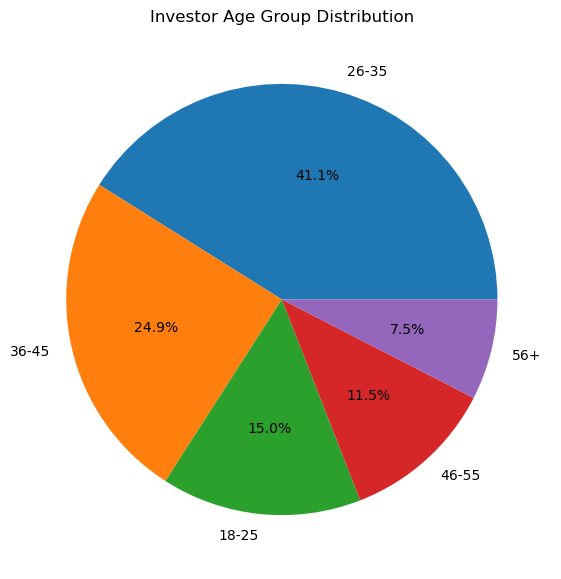

In [25]:
age_count = transactions["age_group"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    age_count,
    labels=age_count.index,
    autopct="%1.1f%%"
)

plt.title("Investor Age Group Distribution")
plt.savefig(CHART_PATH / "age_distribution.png")
plt.show()

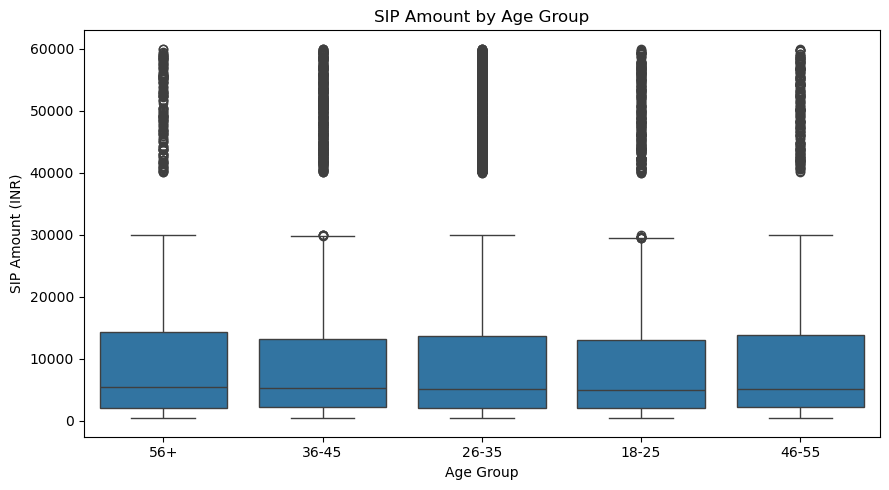

In [26]:
sip_data = transactions[
    transactions["transaction_type"] == "SIP"
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sip_data,
    x="age_group",
    y="amount_inr"
)

plt.title("SIP Amount by Age Group")
plt.xlabel("Age Group")
plt.ylabel("SIP Amount (INR)")
plt.tight_layout()

plt.savefig(CHART_PATH / "sip_by_age.png")
plt.show()

In [ ]:
#### Geographic Distribution

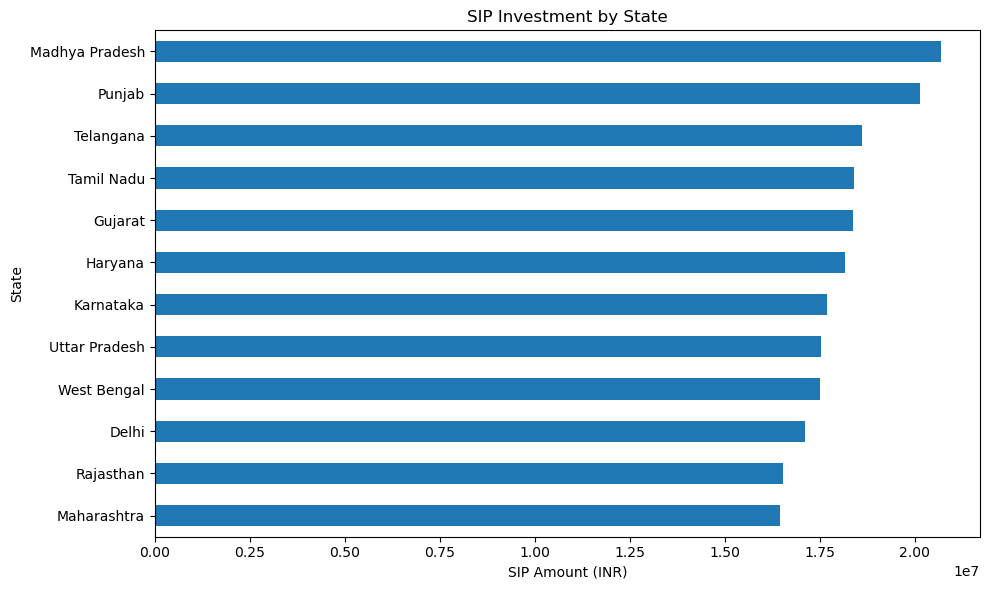

In [27]:
state_data = sip_data.groupby("state")["amount_inr"].sum().sort_values()

plt.figure(figsize=(10, 6))
state_data.plot(kind="barh")

plt.title("SIP Investment by State")
plt.xlabel("SIP Amount (INR)")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(CHART_PATH / "sip_by_state.png")
plt.show()

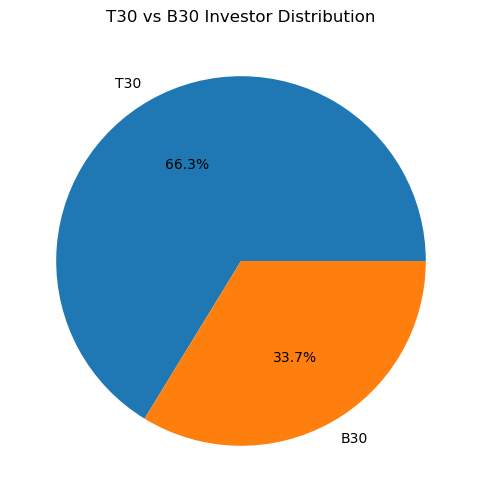

In [28]:
city_data = transactions["city_tier"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(city_data, labels=city_data.index, autopct="%1.1f%%")

plt.title("T30 vs B30 Investor Distribution")
plt.savefig(CHART_PATH / "t30_b30.png")
plt.show()

In [29]:
### Folio Count Growth

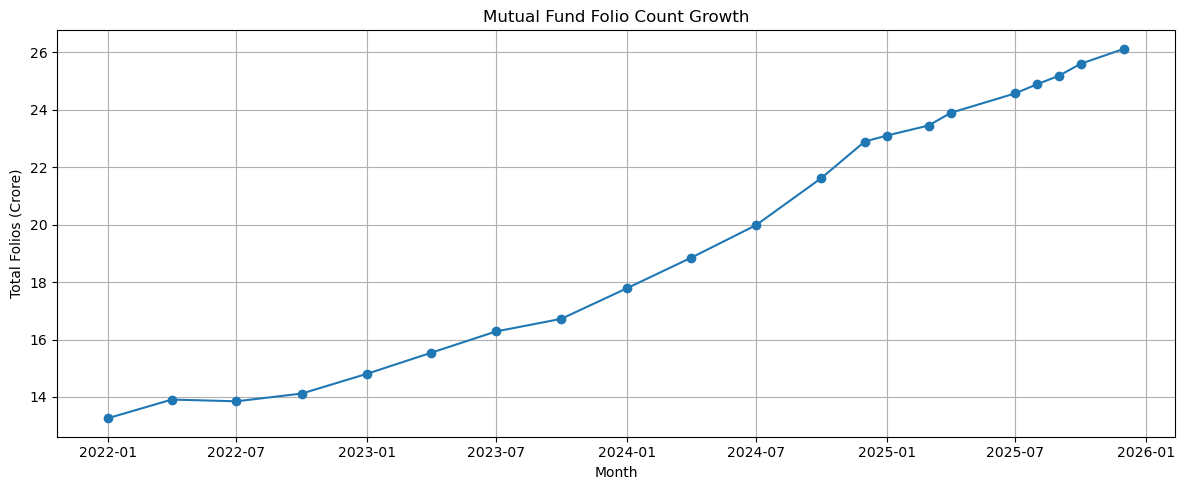

In [30]:
industry_folio["month"] = pd.to_datetime(industry_folio["month"])

industry_folio = industry_folio.sort_values("month")

plt.figure(figsize=(12, 5))

plt.plot(
    industry_folio["month"],
    industry_folio["total_folios_crore"],
    marker="o"
)

plt.title("Mutual Fund Folio Count Growth")
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid()
plt.tight_layout()

plt.savefig(CHART_PATH / "folio_growth.png")
plt.show()

### Correlation Matrix

In [31]:
nav["date"] = pd.to_datetime(nav["date"])

nav_pivot = nav.pivot_table(
    index="date",
    columns="amfi_code",
    values="nav"
)

In [32]:
returns = nav_pivot.pct_change()

correlation = returns.corr()

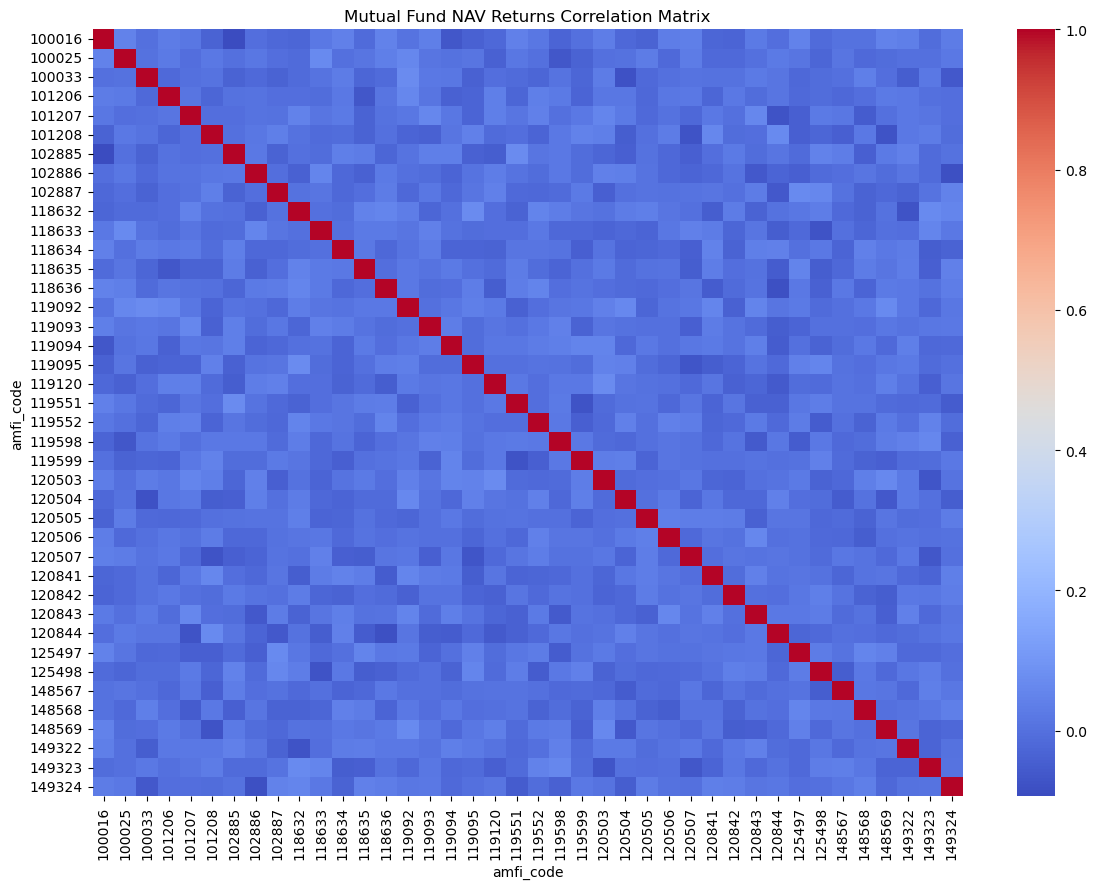

In [33]:
plt.figure(figsize=(12, 9))

sns.heatmap(correlation, cmap="coolwarm", annot=False)

plt.title("Mutual Fund NAV Returns Correlation Matrix")
plt.tight_layout()

plt.savefig(CHART_PATH / "correlation_matrix.png")
plt.show()

In [ ]:
## #Sector Allocation

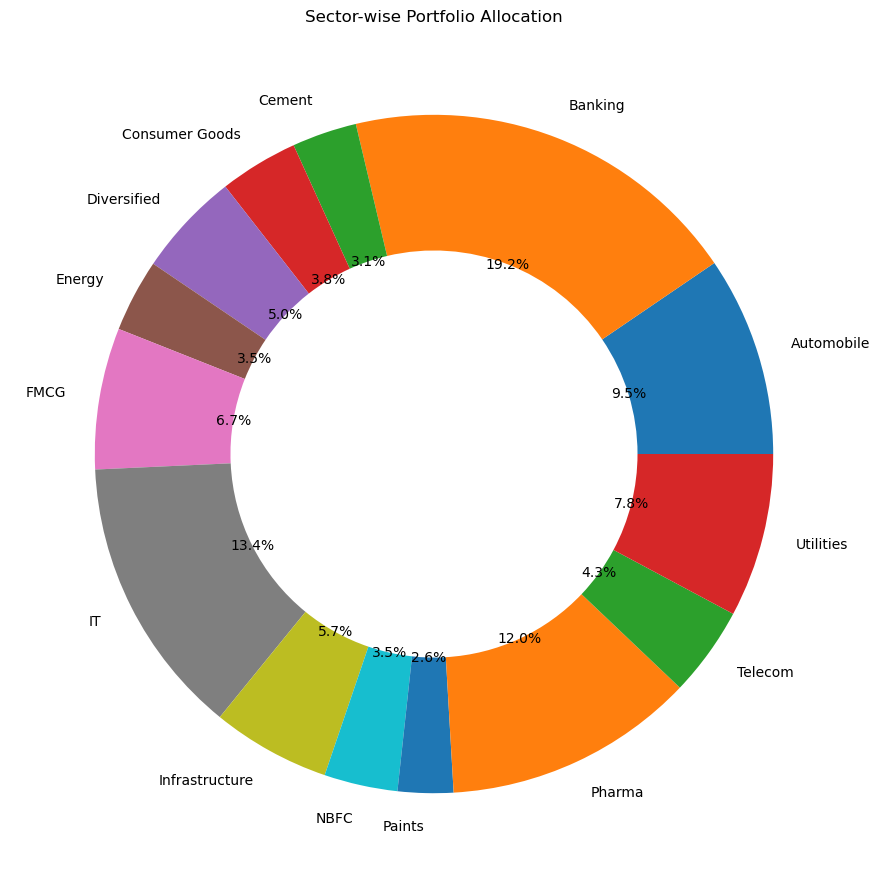

In [34]:
sector_data = portfolio.groupby("sector")["weight_pct"].sum()

plt.figure(figsize=(9, 9))

plt.pie(
    sector_data,
    labels=sector_data.index,
    autopct="%1.1f%%",
    wedgeprops={"width": 0.4}
)

plt.title("Sector-wise Portfolio Allocation")
plt.tight_layout()

plt.savefig(CHART_PATH / "sector_allocation.png")
plt.show()

In [ ]:
## EDA Key Findings

# EDA Key Findings

1. NAV analysis shows changes in mutual fund values over time.
2. AUM analysis compares the assets managed by different fund houses.
3. SIP inflows show monthly investment trends.
4. Category-wise analysis highlights differences in investment inflows.
5. Investor demographics show the distribution of investors across age groups.
6. SIP investment amounts vary across different age groups.
7. Geographic analysis identifies states with higher SIP investments.
8. T30 and B30 analysis compares investor distribution by city tier.
9. Folio analysis shows the growth of mutual fund accounts.
10. Correlation analysis helps understand relationships between fund returns.
11. Sector allocation shows how portfolio investments are distributed across sectors.

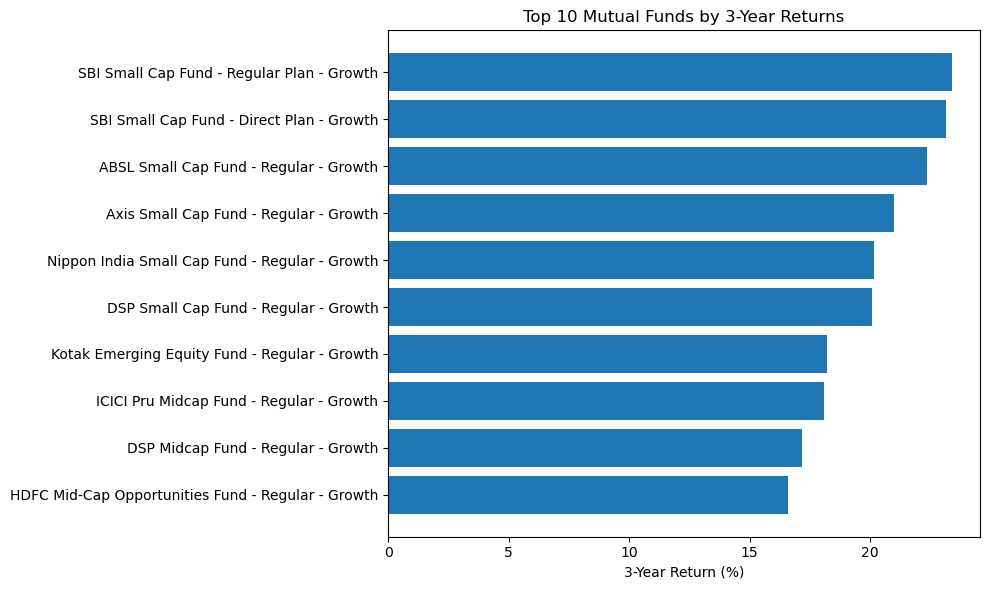

In [35]:
top_funds = performance.sort_values(
    "return_3yr_pct", ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(top_funds["scheme_name"], top_funds["return_3yr_pct"])

plt.title("Top 10 Mutual Funds by 3-Year Returns")
plt.xlabel("3-Year Return (%)")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(CHART_PATH / "top_10_funds.png")
plt.show()

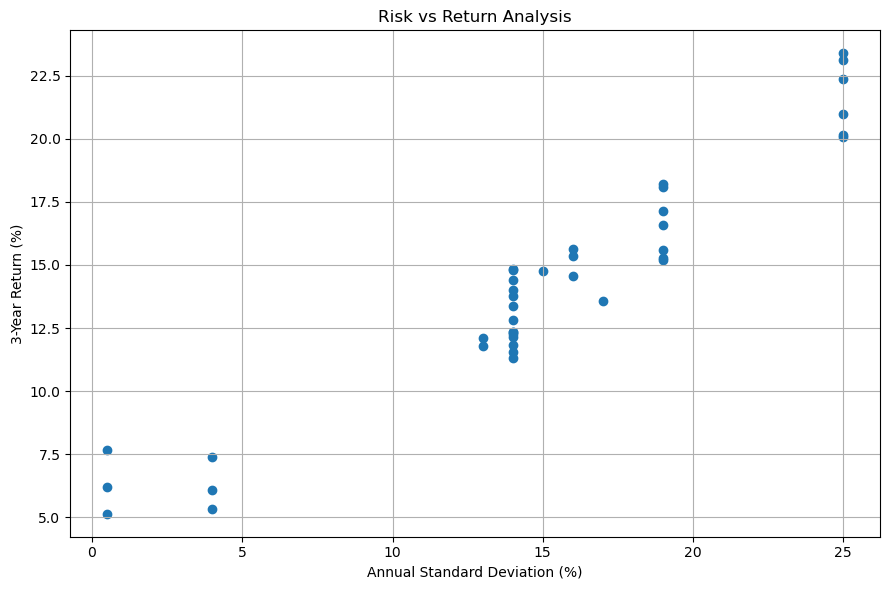

In [36]:
plt.figure(figsize=(9, 6))

plt.scatter(
    performance["std_dev_ann_pct"],
    performance["return_3yr_pct"]
)

plt.title("Risk vs Return Analysis")
plt.xlabel("Annual Standard Deviation (%)")
plt.ylabel("3-Year Return (%)")
plt.grid()
plt.tight_layout()

plt.savefig(CHART_PATH / "risk_vs_return.png")
plt.show()

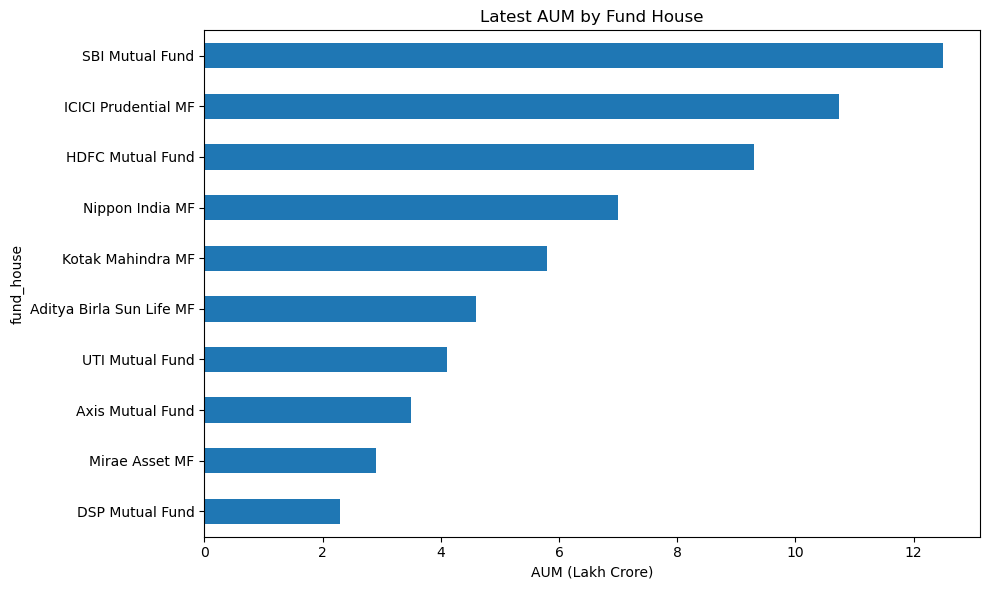

In [37]:
latest_date = aum["date"].max()

latest_aum = aum[aum["date"] == latest_date]

house_aum = latest_aum.groupby("fund_house")[
    "aum_lakh_crore"
].sum().sort_values()

plt.figure(figsize=(10, 6))

house_aum.plot(kind="barh")

plt.title("Latest AUM by Fund House")
plt.xlabel("AUM (Lakh Crore)")
plt.tight_layout()

plt.savefig(CHART_PATH / "latest_aum_by_house.png")
plt.show()

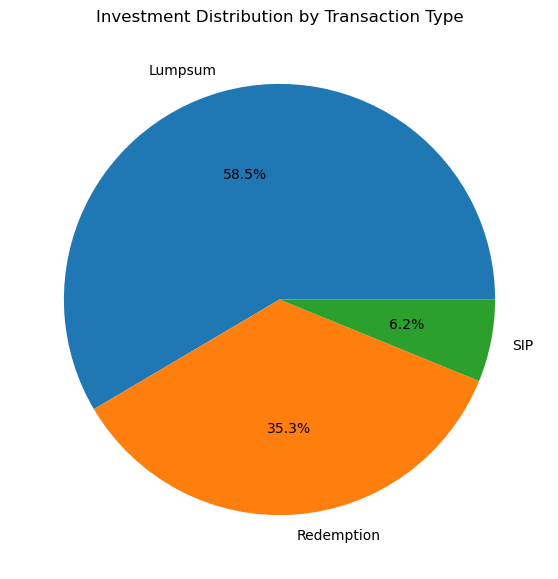

In [38]:
transaction_data = transactions.groupby(
    "transaction_type"
)["amount_inr"].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    transaction_data,
    labels=transaction_data.index,
    autopct="%1.1f%%"
)

plt.title("Investment Distribution by Transaction Type")
plt.savefig(CHART_PATH / "transaction_distribution.png")
plt.show()

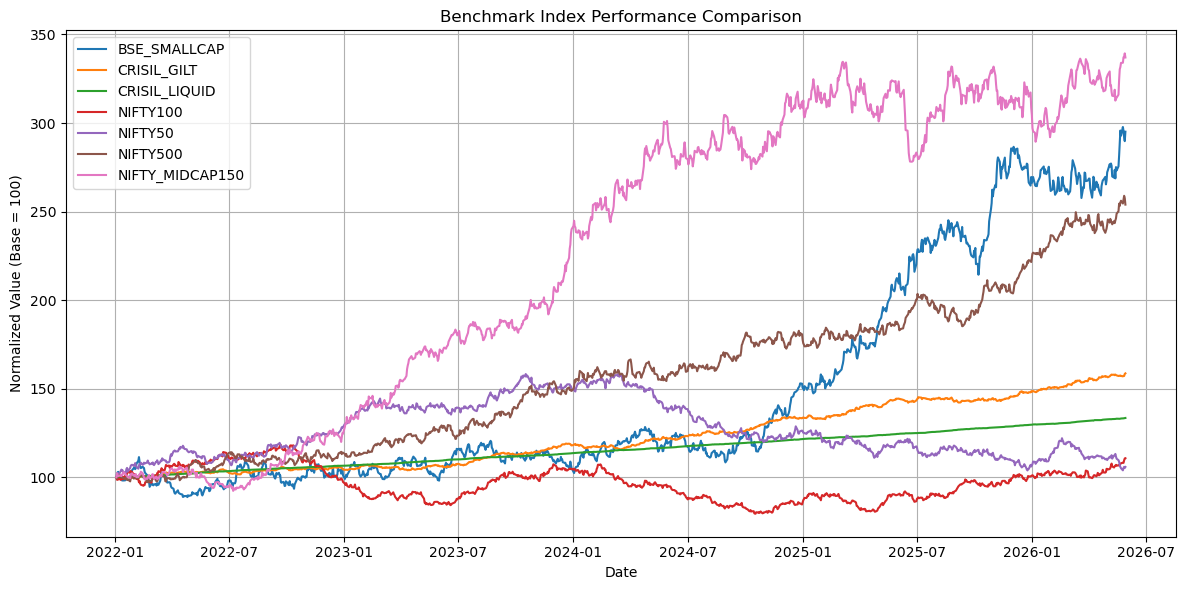

In [39]:
benchmark["date"] = pd.to_datetime(benchmark["date"])

benchmark_pivot = benchmark.pivot_table(
    index="date",
    columns="index_name",
    values="close_value"
)

normalized = benchmark_pivot / benchmark_pivot.iloc[0] * 100

plt.figure(figsize=(12, 6))

for column in normalized.columns:
    plt.plot(normalized.index, normalized[column], label=column)

plt.title("Benchmark Index Performance Comparison")
plt.xlabel("Date")
plt.ylabel("Normalized Value (Base = 100)")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig(CHART_PATH / "benchmark_comparison.png")
plt.show()